In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
# Load the dataset files

train_df = pd.read_csv("train.csv")
meal_df = pd.read_csv("meal_info.csv")
center_df = pd.read_csv("fulfilment_center_info.csv")

print("Datasets loaded successfully!")

print("Training data shape:", train_df.shape)
print("Meal information shape:", meal_df.shape)
print("Center information shape:", center_df.shape)

display(train.head())
display(meal_info.head())
display(center_info.head())

Datasets loaded successfully!
Training data shape: (456548, 9)
Meal information shape: (51, 3)
Center information shape: (77, 5)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian


,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


In [10]:
# Display column names

print("Training columns:")
print(train_df.columns.tolist())

print("\nTraining dataset information:")
train_df.info()

print("\nMissing values:")
print(train_df.isnull().sum())

Training columns:
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 31.3 MB

Missing values:
id                       0
week                     0
cente

In [11]:
# Merge training data with meal information

df = train_df.merge(
    meal_df,
    on="meal_id",
    how="left",
    validate="many_to_one"
)

# Merge with fulfillment center information

df = df.merge(
    center_df,
    on="center_id",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", df.shape)

display(df.head())

Merged dataset shape: (456548, 15)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area
0,1379560,1,55,1885,136.83,152.29,0,0,177,Beverages,Thai,647,56,TYPE_C,2.0
1,1466964,1,55,1993,136.83,135.83,0,0,270,Beverages,Thai,647,56,TYPE_C,2.0
2,1346989,1,55,2539,134.86,135.86,0,0,189,Beverages,Thai,647,56,TYPE_C,2.0
3,1338232,1,55,2139,339.50,437.53,0,0,54,Beverages,Indian,647,56,TYPE_C,2.0
4,1448490,1,55,2631,243.50,242.50,0,0,40,Beverages,Indian,647,56,TYPE_C,2.0


In [12]:
# Remove duplicate rows

df = df.drop_duplicates().copy()

# Remove rows where the target value is missing

df = df.dropna(subset=["num_orders"]).copy()

# Convert target to numeric

df["num_orders"] = pd.to_numeric(
    df["num_orders"],
    errors="coerce"
)

df = df.dropna(subset=["num_orders"]).copy()

# Check for negative demand values

df = df[df["num_orders"] >= 0].copy()

print("Cleaned dataset shape:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Cleaned dataset shape: (456548, 15)

Missing values after cleaning:
id                       0
week                     0
center_id                0
meal_id                  0
checkout_price           0
base_price               0
emailer_for_promotion    0
homepage_featured        0
num_orders               0
category                 0
cuisine                  0
city_code                0
region_code              0
center_type              0
op_area                  0
dtype: int64


In [13]:
# Statistical summary

display(df.describe())

# Average orders

print("Average number of orders:", df["num_orders"].mean())

# Maximum orders

print("Maximum number of orders:", df["num_orders"].max())

# Minimum orders

print("Minimum number of orders:", df["num_orders"].min())

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,op_area
count,4.565480e+05,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.00000,456548.000000,456548.000000,456548.000000,456548.000000
mean,1.250096e+06,74.768771,82.105796,2024.337458,332.238933,354.156627,0.081152,0.10920,261.872760,601.553399,56.614566,4.083590
std,1.443548e+05,41.524956,45.975046,547.420920,152.939723,160.715914,0.273069,0.31189,395.922798,66.195914,17.641306,1.091686
min,1.000000e+06,1.000000,10.000000,1062.000000,2.970000,55.350000,0.000000,0.00000,13.000000,456.000000,23.000000,0.900000
25%,1.124999e+06,39.000000,43.000000,1558.000000,228.950000,243.500000,0.000000,0.00000,54.000000,553.000000,34.000000,3.600000
50%,1.250184e+06,76.000000,76.000000,1993.000000,296.820000,310.460000,0.000000,0.00000,136.000000,596.000000,56.000000,4.000000
75%,1.375140e+06,111.000000,110.000000,2539.000000,445.230000,458.870000,0.000000,0.00000,324.000000,651.000000,77.000000,4.500000
max,1.499999e+06,145.000000,186.000000,2956.000000,866.270000,866.270000,1.000000,1.00000,24299.000000,713.000000,93.000000,7.000000


Average number of orders: 261.8727603669275
Maximum number of orders: 24299
Minimum number of orders: 13


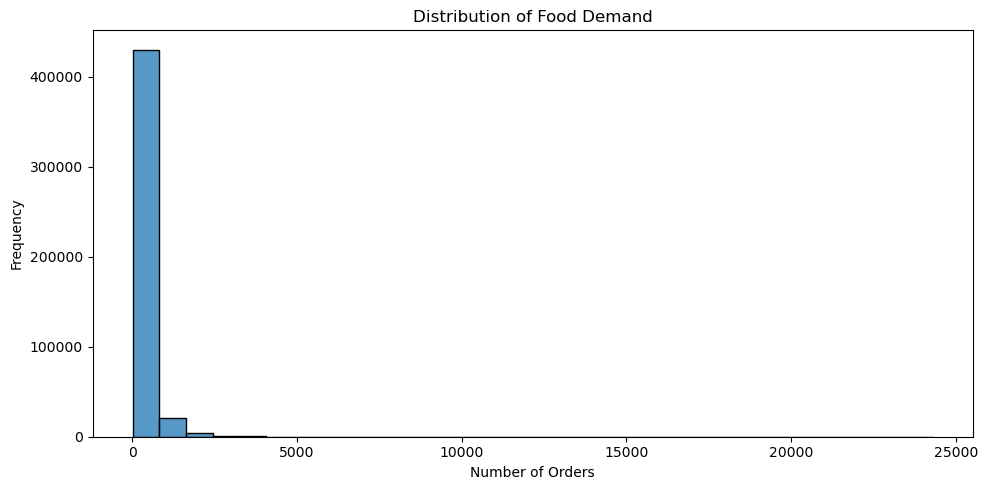

In [14]:
# Distribution of food demand

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="num_orders",
    bins=30
)

plt.title("Distribution of Food Demand")
plt.xlabel("Number of Orders")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

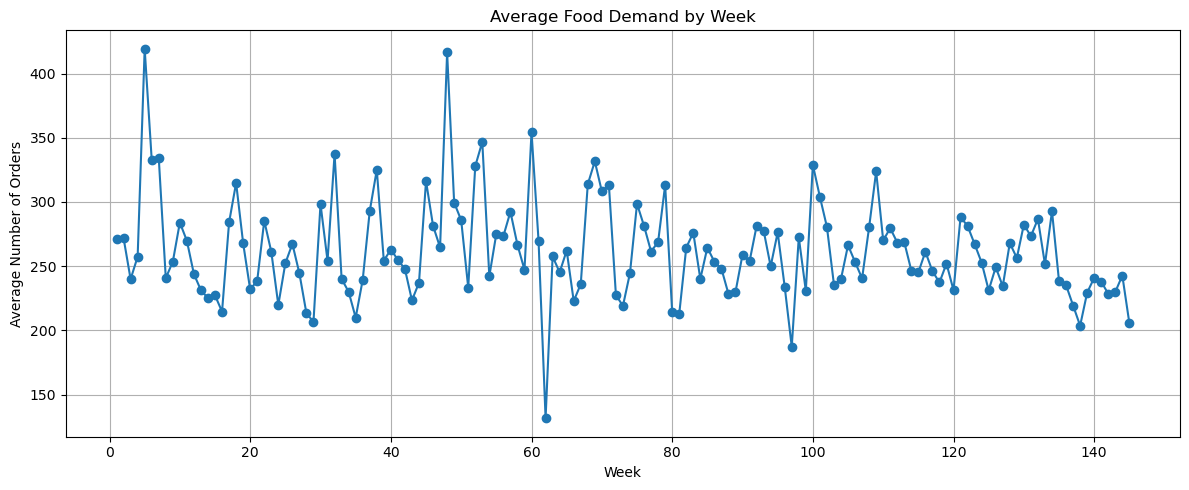

In [15]:
# Calculate average orders for each week

weekly_demand = (
    df.groupby("week")["num_orders"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_demand.index,
    weekly_demand.values,
    marker="o"
)

plt.title("Average Food Demand by Week")
plt.xlabel("Week")
plt.ylabel("Average Number of Orders")

plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# Define input features

features = [
    "week",
    "center_id",
    "meal_id",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "category",
    "cuisine",
    "region_code",
    "center_type",
    "op_area"
]

target = "num_orders"

# Keep only the required columns

X = df[features].copy()
y = df[target].copy()

# Treat categorical variables as categories

categorical_features = [
    "center_id",
    "meal_id",
    "category",
    "cuisine",
    "region_code",
    "center_type"
]

numerical_features = [
    "week",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "op_area"
]

for column in categorical_features:
    X[column] = X[column].astype("string")

print("Input features:", X.shape)
print("Target values:", y.shape)

Input features: (456548, 12)
Target values: (456548,)


In [17]:
# Sort records by week

df = df.sort_values("week").reset_index(drop=True)

# Recreate features and target after sorting

X = df[features].copy()
y = df[target].copy()

for column in categorical_features:
    X[column] = X[column].astype("string")

# Use the earliest 80% of records for training

split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Last training week:", X_train["week"].max())
print("First testing week:", X_test["week"].min())

Training records: 365238
Testing records: 91310
Last training week: 118
First testing week: 118


In [18]:
# Preprocess numerical features

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Preprocess categorical features

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
# Create the complete Machine Learning pipeline

model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Machine Learning model created successfully!")

Machine Learning model created successfully!


In [20]:
# Train the model

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [21]:
# Predict demand for the test records

y_pred = model.predict(X_test)

# Order counts cannot be negative

y_pred = np.maximum(y_pred, 0)

print("Predictions generated successfully!")

print("First 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!
First 10 predictions:
[ 24.80219312  26.72161348  87.67894642 197.53682803 137.61266476
  37.72953624  36.08373322 386.5683254  424.94144802 165.81926601]


In [22]:
# Calculate model evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

MODEL EVALUATION RESULTS
------------------------
MAE:  85.10
RMSE: 181.61
R² Score: 0.7537


In [23]:
# Create a comparison table

results = pd.DataFrame({
    "Actual_Orders": y_test.values,
    "Predicted_Orders": y_pred.round().astype(int)
})

display(results.head(20))

,Actual_Orders,Predicted_Orders
0,13,25
1,13,27
2,69,88
3,242,198
4,54,138
5,14,38
6,69,36
7,514,387
8,609,425
9,122,166


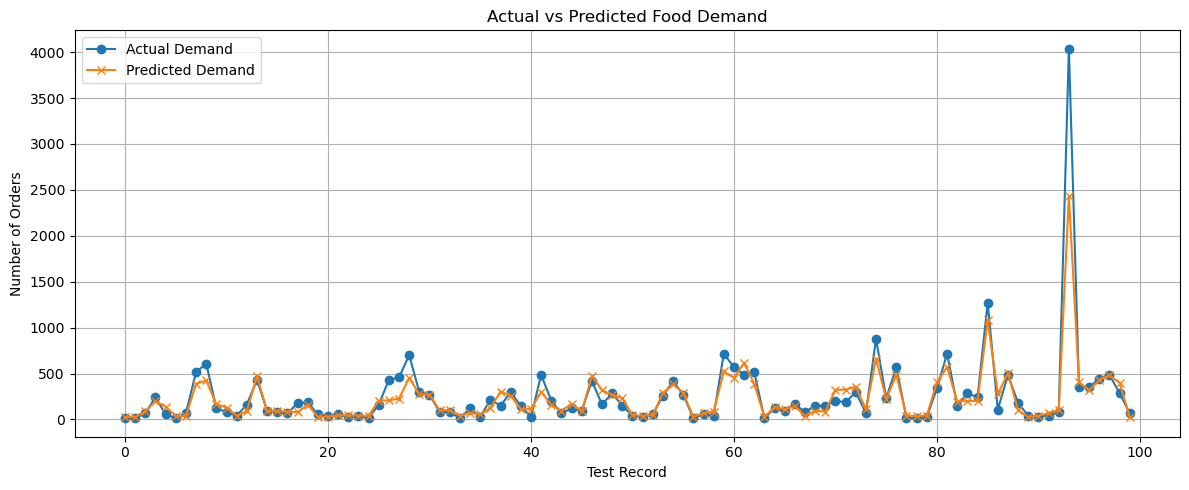

In [24]:
# Select a sample of test records for visualization

sample_size = min(100, len(results))

plot_results = results.head(sample_size)

plt.figure(figsize=(12, 5))

plt.plot(
    range(sample_size),
    plot_results["Actual_Orders"],
    label="Actual Demand",
    marker="o"
)

plt.plot(
    range(sample_size),
    plot_results["Predicted_Orders"],
    label="Predicted Demand",
    marker="x"
)

plt.title("Actual vs Predicted Food Demand")
plt.xlabel("Test Record")
plt.ylabel("Number of Orders")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
# Select one record from the test dataset

new_data = X_test.iloc[[0]].copy()

# Predict its demand

predicted_demand = model.predict(new_data)[0]

print("Example input:")
display(new_data)

print(
    "Predicted number of orders:",
    round(max(0, predicted_demand))
)

Example input:


,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,category,cuisine,region_code,center_type,op_area
365238,118,124,2956,583.03,582.03,0,0,Fish,Continental,56,TYPE_C,4.0


Predicted number of orders: 25


In [26]:
# Save the trained model

joblib.dump(
    model,
    "food_demand_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [27]:
# Save actual and predicted demand

results.to_csv(
    "demand_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [28]:
# Retrieve the fitted preprocessing pipeline

fitted_preprocessor = model.named_steps["preprocessor"]

# Get transformed feature names

feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance

importances = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
1,num__checkout_price,0.174864
5,num__op_area,0.110437
4,num__homepage_featured,0.096428
113,cat__meal_id_2290,0.075586
0,num__week,0.062822
142,cat__category_Rice Bowl,0.056143
2,num__base_price,0.045284
3,num__emailer_for_promotion,0.043185
144,cat__category_Sandwich,0.037590
150,cat__cuisine_Italian,0.026737


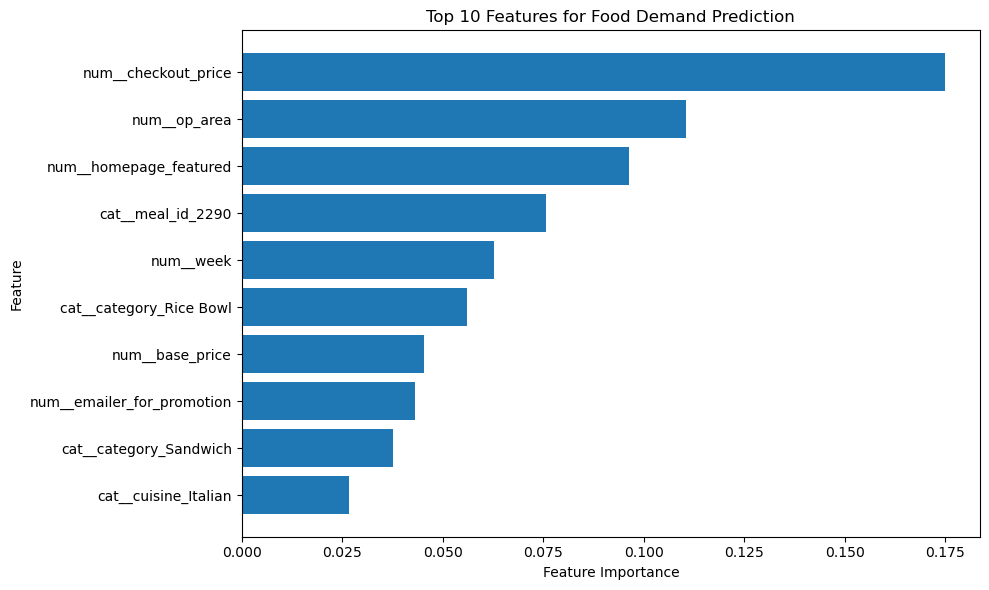

In [29]:
# Plot the top 10 features

top_features = importance_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features for Food Demand Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()